# Задание 53. Ансамбли моделей на данных RemI AI

## 1. Данные и задача

Берём 3000 вымышленных студентов из промежуточной аттестации. По числу правильных начальных ответов по уравнениям и производным предполагаем, покажет ли дополнительная проверка затруднение с производными.

Целевая переменная — needs_review. Значение 1 означает не больше одного правильного ответа из трёх на дополнительной проверке, 0 — два или три. Признаки доступны до этой проверки. Ответы смоделированы программой, а связь между начальными и дополнительными ответами задана при моделировании.

Сравним семь ансамблей и четыре одиночных классификатора. Для запуска нужны pandas, numpy, matplotlib, scikit-learn, lightgbm, xgboost и catboost. Таблица diagnostic_data.csv лежит рядом с блокнотом.

In [1]:
from pathlib import Path
from importlib.metadata import version

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import (
    BaggingClassifier, GradientBoostingClassifier,
    RandomForestClassifier, StackingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, confusion_matrix, f1_score,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

path = Path("diagnostic_data.csv")
if not path.is_file():
    path = Path("cleaned.csv")
data = pd.read_csv(path)
features = ["initial_equations_correct", "initial_derivatives_correct"]
X = data[features]
y = data["needs_review"]

print(f"Студентов: {len(data)}, доля класса 1: {y.mean():.3f}")
for package in ["scikit-learn", "lightgbm", "xgboost", "catboost"]:
    print(package, version(package))

Студентов: 3000, доля класса 1: 0.506
scikit-learn 1.5.2
lightgbm 4.6.0
xgboost 2.1.4
catboost 1.2.8


## 2. Разбиение данных

Повторяем разбиение заданий 47 и 50. Получаем 1800 сессий для обучения, 600 для валидации и 600 для теста. Доли классов примерно одинаковы благодаря stratify.

Параметры подбираем через GridSearchCV только на 1800 обучающих сессиях. Используем три части кросс-валидации и средний F1. На валидации сравним уже настроенные модели и выберем лучший ансамбль. Затем посчитаем итоговые метрики на тесте.

В stacking метамодель обучается на прогнозах для тех строк, которые базовая модель не видела при своём обучении. Это обеспечивает внутренняя кросс-валидация StackingClassifier.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

print(f"Обучение: {len(X_fit)}, валидация: {len(X_val)}, тест: {len(X_test)}")

Обучение: 1800, валидация: 600, тест: 600


## 3. Модели и параметры

Сначала задаём одиночные модели. Масштабирование для KNN, логистической регрессии и SVM включаем в Pipeline. Поэтому на каждом шаге кросс-валидации масштаб рассчитывается по текущей обучающей части.

Bagging обучает несколько деревьев на выборках с возвращением. Random Forest дополнительно выбирает случайное подмножество признаков при разбиениях. Stacking объединяет прогнозы KNN, логистической регрессии и SVM через ещё одну логистическую регрессию.

Четыре варианта бустинга последовательно добавляют деревья. Для каждого попробуем число деревьев и их глубину. Сетки небольшие, чтобы сравнение можно было повторить на обычном компьютере. Пороги оставляем стандартными для моделей.

In [3]:
single_models = {
    "KNN": (
        make_pipeline(StandardScaler(), KNeighborsClassifier()),
        {"kneighborsclassifier__n_neighbors": [5, 25, 101]},
    ),
    "Logistic Regression": (
        make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        {"logisticregression__C": [0.1, 1, 10]},
    ),
    "SVM": (
        make_pipeline(StandardScaler(), SVC()),
        [
            {"svc__kernel": ["linear"], "svc__C": [0.1, 1]},
            {"svc__kernel": ["rbf"], "svc__C": [0.1, 1], "svc__gamma": [0.1, "scale"]},
        ],
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42),
        {"max_depth": [1, 2, 3], "min_samples_leaf": [1, 50]},
    ),
}

stacking = StackingClassifier(
    estimators=[
        ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25))),
        ("logistic", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
        ("svm", make_pipeline(StandardScaler(), SVC(kernel="linear", C=1))),
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3, n_jobs=1,
)

ensemble_models = {
    "Stacking": (stacking, {"final_estimator__C": [0.1, 1], "passthrough": [False, True]}),
    "Bagging": (
        BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                          bootstrap=True, random_state=42, n_jobs=1),
        {"n_estimators": [20, 60], "estimator__max_depth": [1, 3]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=1),
        {"n_estimators": [30, 80], "max_depth": [1, 3]},
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(learning_rate=0.05, random_state=42),
        {"n_estimators": [30, 80], "max_depth": [1, 3]},
    ),
    "LightGBM": (
        LGBMClassifier(learning_rate=0.05, random_state=42, verbosity=-1, n_jobs=1),
        {"n_estimators": [30, 80], "max_depth": [1, 3]},
    ),
    "XGBoost": (
        XGBClassifier(learning_rate=0.05, eval_metric="logloss",
                      random_state=42, n_jobs=1),
        {"n_estimators": [30, 80], "max_depth": [1, 3]},
    ),
    "CatBoost": (
        CatBoostClassifier(learning_rate=0.05, random_seed=42, verbose=False,
                           thread_count=1, allow_writing_files=False),
        {"iterations": [30, 80], "depth": [1, 3]},
    ),
}
configurations = {**single_models, **ensemble_models}
print(f"Одиночных моделей: {len(single_models)}, ансамблей: {len(ensemble_models)}")

Одиночных моделей: 4, ансамблей: 7


## 4. Подбор параметров и сравнение на валидации

Для каждой модели выбираем набор параметров с наибольшим средним F1 на кросс-валидации. Если оценки равны, GridSearchCV оставляет первый вариант в порядке перебора.

Accuracy — доля верных ответов. Precision — доля настоящих затруднений среди положительных прогнозов. Recall — доля найденных затруднений среди фактических. F1 учитывает precision и recall. ROC-AUC считаем по вероятностям или decision_function.

После настройки модели остаются обученными на тех же 1800 сессиях. Это сохраняет условия сравнения между валидацией и тестом.

In [4]:
def calculate_metrics(name, model, X_part, y_part):
    prediction = model.predict(X_part)
    if hasattr(model, "predict_proba"):
        score = model.predict_proba(X_part)[:, 1]
    else:
        score = model.decision_function(X_part)
    return {
        "Модель": name,
        "Accuracy": accuracy_score(y_part, prediction),
        "Precision": precision_score(y_part, prediction, zero_division=0),
        "Recall": recall_score(y_part, prediction),
        "F1": f1_score(y_part, prediction),
        "ROC-AUC": roc_auc_score(y_part, score),
    }

models = {}
search_results = []
validation_results = []
for name, (estimator, parameters) in configurations.items():
    search = GridSearchCV(
        estimator, parameters, scoring="f1", cv=cv, n_jobs=1, error_score="raise"
    )
    search.fit(X_fit, y_fit)
    models[name] = search.best_estimator_
    search_results.append({
        "Модель": name, "Средний F1 CV": search.best_score_,
        "Параметры": search.best_params_,
    })
    validation_results.append(calculate_metrics(name, models[name], X_val, y_val))
    print(f"{name}: средний F1 CV = {search.best_score_:.4f}")

display(pd.DataFrame(search_results).set_index("Модель"))
validation = pd.DataFrame(validation_results).set_index("Модель")
display(validation.round(4))

best_ensemble = validation.loc[list(ensemble_models), "F1"].idxmax()
best_single = validation.loc[list(single_models), "F1"].idxmax()
print(f"Выбранный ансамбль по валидации: {best_ensemble}")
print(f"Выбранная одиночная модель по валидации: {best_single}")

KNN: средний F1 CV = 0.6748
Logistic Regression: средний F1 CV = 0.6468


SVM: средний F1 CV = 0.7061
Decision Tree: средний F1 CV = 0.7085


Stacking: средний F1 CV = 0.7043


Bagging: средний F1 CV = 0.7085


Random Forest: средний F1 CV = 0.7043


Gradient Boosting: средний F1 CV = 0.7085


... (2 outputs left out)

CatBoost: средний F1 CV = 0.7051


,Средний F1 CV,Параметры
Модель,,
KNN,0.674814,{'kneighborsclassifier__n_neighbors': 101}
Logistic Regression,0.646766,{'logisticregression__C': 0.1}
SVM,0.706124,"{'svc__C': 1, 'svc__kernel': 'linear'}"
Decision Tree,0.708496,"{'max_depth': 1, 'min_samples_leaf': 1}"
Stacking,0.704321,"{'final_estimator__C': 1, 'passthrough': True}"
Bagging,0.708496,"{'estimator__max_depth': 1, 'n_estimators': 20}"
Random Forest,0.704321,"{'max_depth': 3, 'n_estimators': 30}"
Gradient Boosting,0.708496,"{'max_depth': 1, 'n_estimators': 30}"
LightGBM,0.708496,"{'max_depth': 1, 'n_estimators': 30}"


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
KNN,0.6683,0.7031,0.5941,0.6440,0.7102
Logistic Regression,0.6683,0.7031,0.5941,0.6440,0.7074
SVM,0.6267,0.7207,0.4257,0.5353,0.7074
Decision Tree,0.6217,0.5892,0.8284,0.6886,0.6196
Stacking,0.6433,0.6199,0.7591,0.6825,0.7074
Bagging,0.6217,0.5892,0.8284,0.6886,0.6196
Random Forest,0.6433,0.6199,0.7591,0.6825,0.7094
Gradient Boosting,0.6217,0.5892,0.8284,0.6886,0.6903
LightGBM,0.6217,0.5892,0.8284,0.6886,0.6903


Выбранный ансамбль по валидации: Bagging
Выбранная одиночная модель по валидации: Decision Tree


## 5. Итоговые метрики на тесте

Выбранный ансамбль и одиночная модель уже определены по валидации. Теперь покажем тестовые результаты всех моделей, чтобы выполнить сравнение из условия задания.

Добавим прогноз самым частым классом из обучения. Для всех моделей используем одинаковые 600 тестовых сессий.

,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
KNN,0.6617,0.6866,0.6073,0.6445,0.7318
Logistic Regression,0.6617,0.6866,0.6073,0.6445,0.7288
SVM,0.6300,0.7098,0.4521,0.5524,0.7288
Decision Tree,0.6500,0.6115,0.8416,0.7083,0.6481
Stacking,0.6767,0.6485,0.7855,0.7104,0.7288
Bagging,0.6500,0.6115,0.8416,0.7083,0.6481
Random Forest,0.6767,0.6485,0.7855,0.7104,0.7204
Gradient Boosting,0.6500,0.6115,0.8416,0.7083,0.7201
LightGBM,0.6500,0.6115,0.8416,0.7083,0.7201


Выбранный на валидации ансамбль


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Bagging,0.65,0.6115,0.8416,0.7083,0.6481


Выбранная на валидации одиночная модель


,Accuracy,Precision,Recall,F1,ROC-AUC
Модель,,,,,
Decision Tree,0.65,0.6115,0.8416,0.7083,0.6481


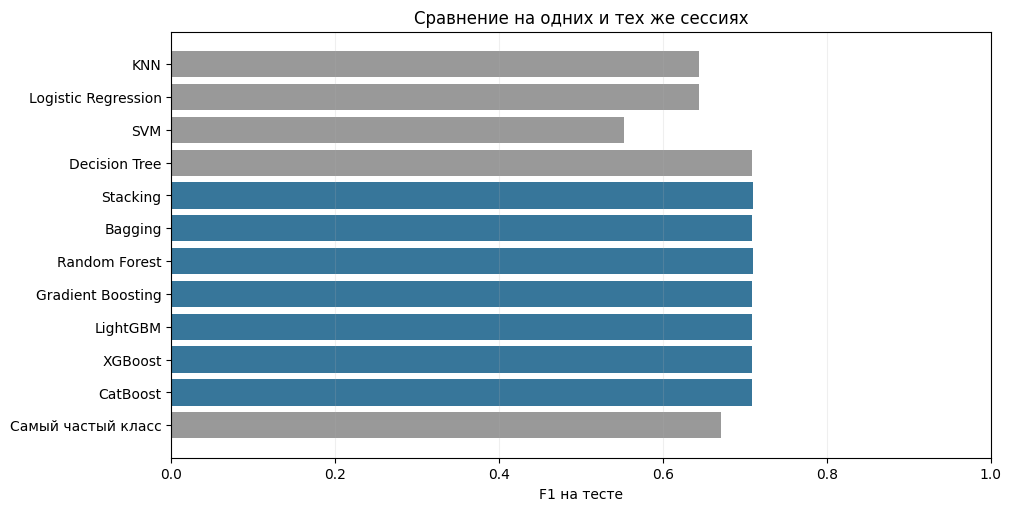

In [5]:
test_results = [
    calculate_metrics(name, model, X_test, y_test) for name, model in models.items()
]
majority = int(y_fit.mode().iloc[0])
baseline = [majority] * len(y_test)
test_results.append({
    "Модель": "Самый частый класс",
    "Accuracy": accuracy_score(y_test, baseline),
    "Precision": precision_score(y_test, baseline, zero_division=0),
    "Recall": recall_score(y_test, baseline),
    "F1": f1_score(y_test, baseline),
    "ROC-AUC": 0.5,
})
test = pd.DataFrame(test_results).set_index("Модель")
display(test.round(4))

print("Выбранный на валидации ансамбль")
display(test.loc[[best_ensemble]].round(4))
print("Выбранная на валидации одиночная модель")
display(test.loc[[best_single]].round(4))

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
colors = ["#37769a" if name in ensemble_models else "0.6" for name in test.index]
ax.barh(test.index, test["F1"], color=colors)
ax.set(xlabel="F1 на тесте", title="Сравнение на одних и тех же сессиях", xlim=(0, 1))
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
plt.show()

## 6. Матрицы ошибок

Для каждого ансамбля и одиночного классификатора показываем матрицу ошибок. Строки — фактический класс, столбцы — прогноз. Внизу справа — найденные затруднения, внизу слева — пропущенные, вверху справа — ложные срабатывания.

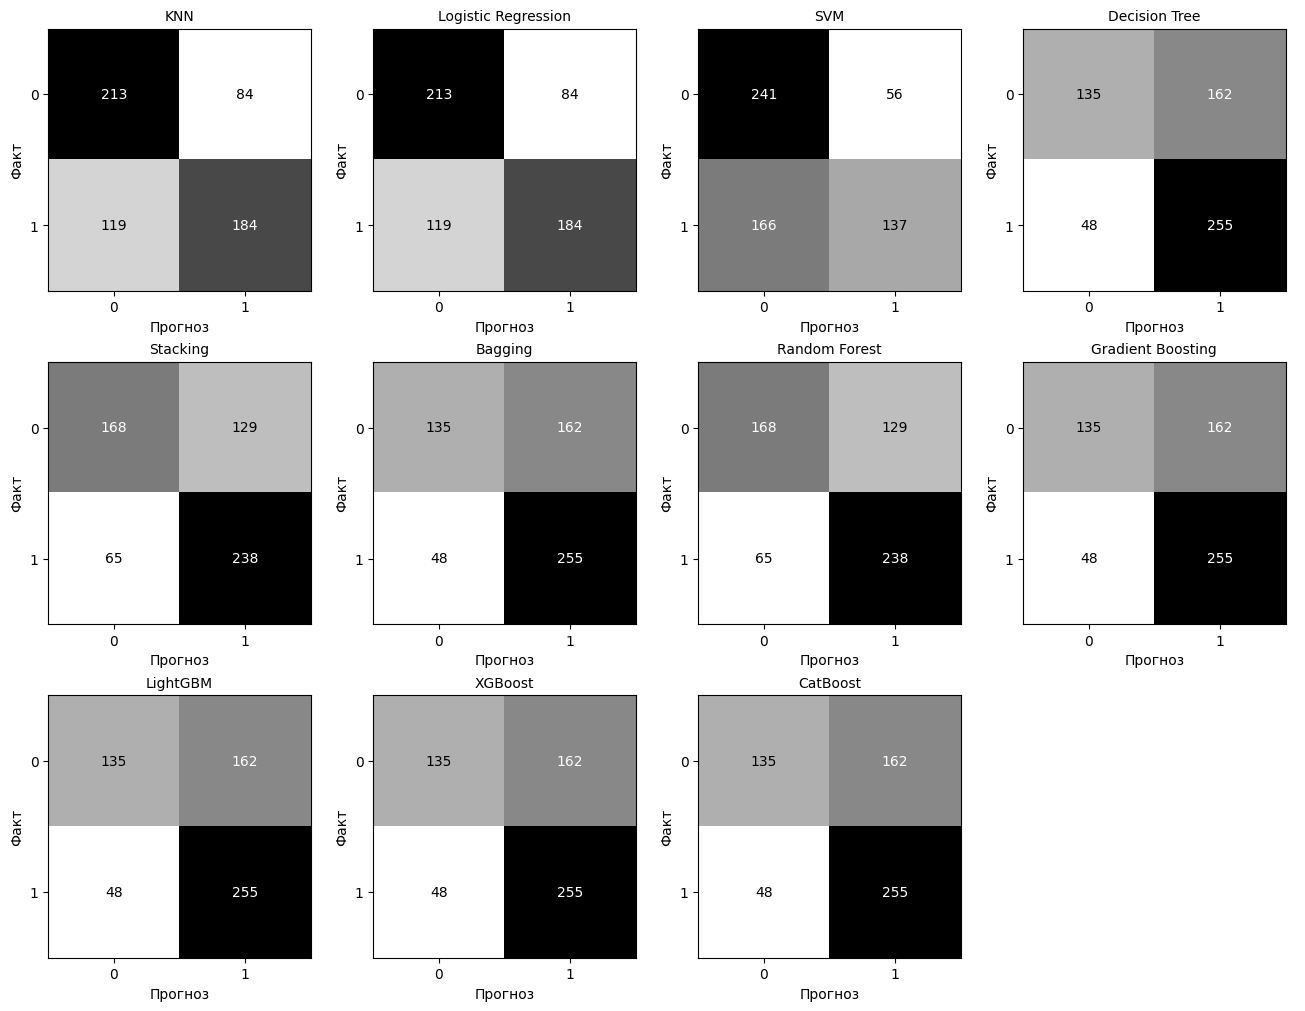

,Найдено,Пропущено,Ложных срабатываний,Верно класс 0
Модель,,,,
KNN,184,119,84,213
Logistic Regression,184,119,84,213
SVM,137,166,56,241
Decision Tree,255,48,162,135
Stacking,238,65,129,168
Bagging,255,48,162,135
Random Forest,238,65,129,168
Gradient Boosting,255,48,162,135
LightGBM,255,48,162,135


In [6]:
fig, axes = plt.subplots(3, 4, figsize=(13, 10), layout="constrained")
error_rows = []
for ax, (name, model) in zip(axes.ravel(), models.items()):
    matrix = confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=["0", "1"]).plot(
        ax=ax, colorbar=False, cmap="Greys"
    )
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Прогноз")
    ax.set_ylabel("Факт")
    tn, fp, fn, tp = matrix.ravel()
    error_rows.append({
        "Модель": name, "Найдено": tp, "Пропущено": fn,
        "Ложных срабатываний": fp, "Верно класс 0": tn,
    })
axes.ravel()[-1].axis("off")
plt.show()
display(pd.DataFrame(error_rows).set_index("Модель"))

## 7. Выводы

Обучены все семь ансамблей из задания. Для каждого параметры подобраны через GridSearchCV на обучающей части. Одиночные модели обучены заново на тех же данных со стандартными порогами, поэтому сравнение внутри этой работы проводится в одинаковых условиях.

На валидации максимальный F1 среди ансамблей равен примерно 0,689. Его дали Bagging, Gradient Boosting, LightGBM, XGBoost и CatBoost. По порядку сравнения выбран Bagging. Среди одиночных моделей выбран Decision Tree с таким же F1.

На тесте выбранные Bagging и Decision Tree получили одинаковые метрики. Accuracy равна 0,650, precision — 0,612, recall — 0,842, F1 — 0,708. Оба нашли 255 из 303 затруднений, пропустили 48 и дали 162 ложных срабатывания.

Stacking и Random Forest получили на тесте F1 около 0,710. Они нашли 238 затруднений, пропустили 65 и дали 129 ложных срабатываний. У них выше precision, но ниже recall, чем у выбранного Bagging. Разница F1 мала, а выбор ансамбля в работе уже сделан по валидации.

Четыре реализации бустинга дали те же матрицы ошибок, что и одиночное дерево. При этом ROC-AUC различается, поскольку модели по-разному ранжируют вероятность затруднения. У Gradient Boosting, LightGBM и XGBoost ROC-AUC около 0,720, у CatBoost — около 0,729, у дерева — около 0,648.

Ансамбли в этом сравнении не дали заметного улучшения F1 относительно одиночного дерева. У нас всего два признака с девятью сочетаниями значений. Студенты с одинаковыми начальными ответами могут получить разные результаты дополнительной проверки, а модели получают о них одинаковую информацию.

Для RemI AI работа показывает порядок сравнения ансамблей и простых классификаторов. Результаты относятся к синтетическим данным и выбранным небольшим сеткам параметров. Вывод о пользе конкретной модели для настоящих студентов потребует реальных ответов и отдельной проверки.
